# Choosing and designing charts

A chart is an argument made with position, length and colour. This notebook covers how to choose a chart for a question, what perception research says about reading charts, and how to use colour, labels and annotation so that every reader, including readers with a colour vision deficiency, sees the point. The code uses the three plotting libraries of the course: **matplotlib** (the base library, full control), **seaborn** (statistical charts from a DataFrame) and **Plotly** (interactive charts in the browser). The page ends with a chart critique, which the exercises of the first block build on.

```mermaid
flowchart TD
    Q{"What is the question?"} -->|"which values occur?"| D["distribution:<br/>histogram, box plot"]
    Q -->|"which group is larger?"| C["comparison:<br/>bars from zero, dot plot"]
    Q -->|"do two numbers move together?"| R["relationship:<br/>scatter plot"]
    Q -->|"how did it change?"| T["change over time:<br/>line chart"]
    Q -->|"what share of a whole?"| P["composition:<br/>stacked bar; pie only for 2–3 parts"]
    D & C & R & T & P --> L["then: library<br/>static report: matplotlib/seaborn<br/>exploration or dashboard: Plotly"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## Choosing a chart for the question

### Concept

Start from the question, not from the chart type. Four questions cover most analyses:

- **Distribution**: which values occur and how often? Histogram, density plot, box plot.
- **Comparison** of a quantity between groups: bars that start at zero, or dots.
- **Relationship** between two numeric variables: scatter plot.
- **Change over time**: line chart with time on the horizontal axis.

Worked example: "Has demand for Berlin listings recovered since the pandemic?" is a change-over-time question about one number per month (reviews, a proxy for stays), so a line chart answers it. "Which district is most expensive?" is a comparison of one number per district: sorted bars. A pie chart per year or per district would force the reader to compare angles across many pies.

### Why it matters

The same data can answer different questions. A chart that fits the question makes the answer visible in seconds; a poorly chosen one hides it. Exploratory charts are also the first data check: gaps and spikes show up before any model is fitted.

### How it works in Python

{'Reinickendorf': 100.0, 'Mitte': 187.0}
2026-05-01 15024


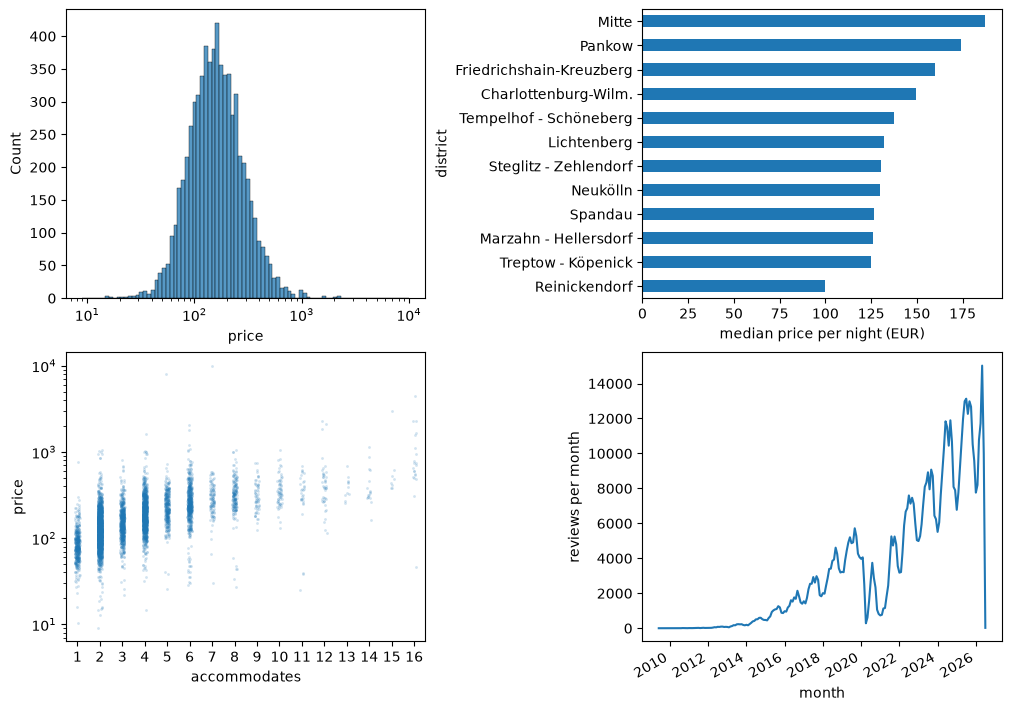

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]   # comparable prices
monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")      # reviews per listing and month

fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
sns.histplot(short, x="price", log_scale=True, ax=axes[0, 0])                    # distribution
median_price = short.groupby("district")["price"].median().sort_values()
median_price.plot.barh(ax=axes[0, 1], xlabel="median price per night (EUR)")      # comparison
sns.stripplot(short, x="accommodates", y="price", alpha=0.2, size=2, ax=axes[1, 0]).set(yscale="log")   # relationship
per_month = monthly.groupby("month")["n_reviews"].sum()
per_month.plot(ax=axes[1, 1], ylabel="reviews per month")                         # change over time

print(median_price.round(0).iloc[[0, -1]].to_dict())   # {'Reinickendorf': 100.0, 'Mitte': 187.0}
print(per_month.idxmax().date(), per_month.max())       # 2026-05-01 15024

### In practice

- The Financial Times *Visual Vocabulary* poster organises chart types by exactly these questions (deviation, correlation, ranking, distribution, change over time, part-to-whole).
- The UK Government Analysis Function publishes guidance on choosing charts for official statistics.
- Epidemic dashboards during COVID-19 (for example by the Robert Koch Institute and Our World in Data) showed daily cases as lines over time and compared regions with small multiples.

> **Tip.** Write the question as a sentence above the chart before you code it. If you cannot, you are not ready to choose a chart.

## Perception and the data–ink ratio

### Concept

A chart **encodes** numbers as visual properties: position, length, angle, area, colour. Cleveland and McGill (1984) measured how accurately people decode them. **Position on a common scale** is read most accurately, then length, then angle and area; colour saturation is least accurate. A bar chart uses position and length; a pie chart uses angle and area.

```mermaid
flowchart LR
    A["position on a<br/>common scale"] --> B["length"] --> C["angle, slope"] --> D["area"] --> E["colour<br/>saturation"]
    style A fill:#0072B2,color:#fff
    style E fill:#eeeeee
```

Tufte's **data–ink ratio** is the share of ink that shows data. Gridlines, borders, shadows and 3D effects that carry no information (**chartjunk**) should be reduced, and values can often be labelled directly instead of in a legend. Wilke's **principle of proportional ink**: the area of a shaded region must be proportional to the value it represents. This is why bars start at zero.

### Why it matters

Readers decide from what they see, not from the underlying table. Encodings that are decoded inaccurately lead to wrong comparisons, and clutter slows the reader down.

### How it works in Python

{'Mitte': 0.221, 'Friedrichshain-Kreuzberg': 0.208, 'Pankow': 0.153, 'Charlottenburg-Wilm.': 0.112, 'Neukölln': 0.102, 'other 7 districts': 0.204}


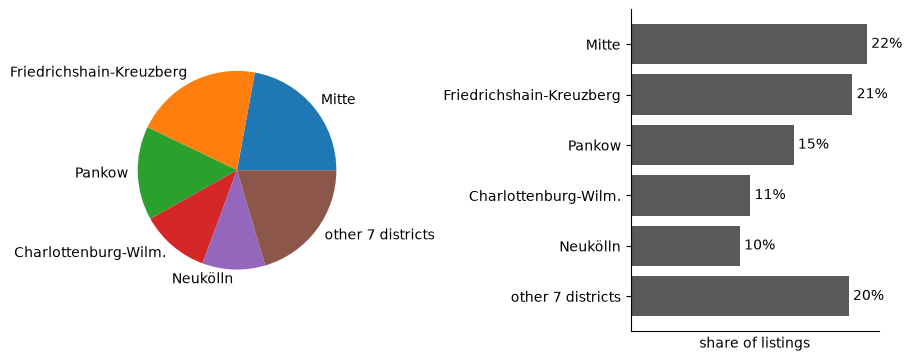

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
share = listings["district"].value_counts(normalize=True)
share = pd.concat([share.head(5), pd.Series({"other 7 districts": share.iloc[5:].sum()})])
print(share.round(3).to_dict())
# {'Mitte': 0.221, 'Friedrichshain-Kreuzberg': 0.208, 'Pankow': 0.153, 'Charlottenburg-Wilm.': 0.112,
#  'Neukölln': 0.102, 'other 7 districts': 0.204}

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.5), layout="constrained")
left.pie(share, labels=share.index)                         # angles and areas: hard to compare
right.barh(share.index, share, color="0.35")                # positions on a common scale
right.bar_label(right.containers[0], labels=[f"{v:.0%}" for v in share], padding=3)
right.spines[["top", "right"]].set_visible(False)           # remove non-data ink
right.set(xlabel="share of listings", ylabel="", xticks=[])
right.invert_yaxis()                                        # largest at the top

### In practice

- The UK Government Analysis Function guidance recommends bar charts instead of pie charts when categories are similar in size.
- Clinical trial reports use forest plots, which place every effect estimate on a common scale.
- Survey reports usually show agreement scales as stacked or diverging bars rather than as a series of pies.

> **Warning.** **3D charts and dual axes.** A 3D bar chart distorts length through perspective. A chart with two y-axes lets the author choose the scales so that any two lines appear to cross. Use two charts side by side instead.

## matplotlib: figures, axes, labels and annotation

### Concept

matplotlib is the base plotting library of Python; pandas and seaborn draw with it. A **Figure** is the whole canvas; an **Axes** is one plot inside it, with its own x- and y-axis. `fig, ax = plt.subplots()` creates both, and all drawing is done with methods of `ax` (`ax.bar`, `ax.set`, `ax.annotate`). This **object-oriented interface** says explicitly which plot is changed.

Every chart for a reader needs axis labels with units, a readable number format and a title. A title that states the finding ("Mitte and Friedrichshain-Kreuzberg hold 43 % of all listings") tells the reader what to look for. `ax.annotate` points to a data point with text and an arrow; one highlighted colour draws attention to the category discussed.

### Why it matters

Charts in reports are read without the analyst present. Labels, a finding title and a targeted annotation make them self-explanatory, and the explicit interface makes figures reproducible.

### How it works in Python

Figure Axes
{'Mitte': 2826, 'Friedrichshain-Kreuzberg': 2652} 0.429


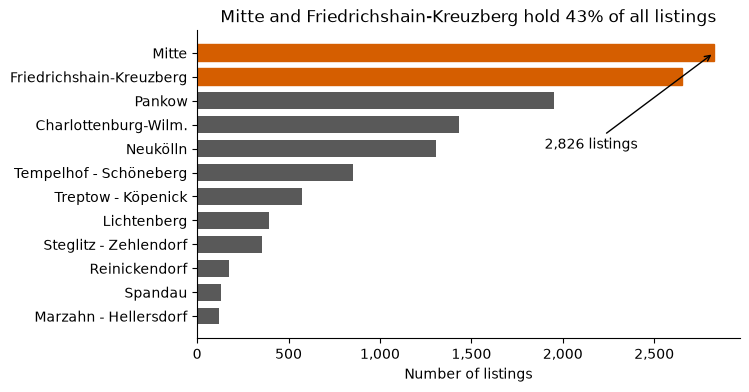

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
counts = listings["district"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))                    # Figure = canvas, Axes = one plot
bars = ax.barh(counts.index, counts, color="0.35", height=0.7)
for bar in bars[:2]:
    bar.set_color("#D55E00")                              # highlight the categories discussed
ax.invert_yaxis()
top2 = counts.iloc[:2].sum() / counts.sum()
ax.set(xlabel="Number of listings", ylabel="",
       title=f"Mitte and Friedrichshain-Kreuzberg hold {top2:.0%} of all listings")
ax.annotate(f"{counts['Mitte']:,} listings", xy=(counts["Mitte"], 0), xytext=(1900, 4),
            arrowprops={"arrowstyle": "->"})
ax.spines[["top", "right"]].set_visible(False)
ax.xaxis.set_major_formatter("{x:,.0f}")                  # 2,000 instead of 2000
import tempfile                                          # save outside the repository
fig.savefig(Path(tempfile.gettempdir()) / "listings_by_district.png", dpi=200, bbox_inches="tight")   # fixed size and resolution
print(type(fig).__name__, type(ax).__name__)             # Figure Axes
print(counts.iloc[:2].to_dict(), round(top2, 3))         # {'Mitte': 2826, 'Friedrichshain-Kreuzberg': 2652} 0.429

### In practice

- Scientific journals require labelled axes with units and often vector formats (PDF, SVG), which `fig.savefig` produces.
- Data journalism annotates charts to guide readers, for example by marking a policy change on a time axis.
- Analysis reports generated from notebooks save matplotlib figures at a fixed size so that they look the same in every version of the report.

> **Tip.** Use the implicit `plt.plot(...)` style only for a quick look. As soon as there is more than one panel, switch to `fig, ax = plt.subplots(...)`.

## Colour and accessibility

### Concept

Colour has three jobs:

- a **qualitative** palette distinguishes unordered categories with clearly different hues;
- a **sequential** palette (light to dark, for example viridis) shows ordered magnitudes;
- a **diverging** palette uses two hues around a neutral midpoint for values above and below a reference.

About 8 % of men and 0.5 % of women of Northern European descent have a red–green colour vision deficiency. **Colour-blind-safe** palettes such as Okabe–Ito (seaborn's `"colorblind"` palette is similar) and the viridis colour maps stay distinguishable for them. Colour should never be the only carrier of meaning: add direct labels, position, marker shape or line style, and keep one fixed colour per category across all charts.

### Why it matters

A chart that part of the audience cannot read fails its purpose. Accessibility rules apply to many public-sector publications, and consistent colours across a dashboard let readers learn the mapping once.

### How it works in Python

['#0173b2', '#de8f05', '#029e73']
room_type      Entire home/apt  Private room  other
district                                           
Pankow                   0.779         0.211  0.010
Reinickendorf            0.551         0.438  0.011


[Text(0.5, 0, 'share of listings'),
 Text(0, 0.5, ''),
 Text(0.5, 1.0, 'Private rooms: one listing in five in Pankow, more than two in five in Reinickendorf')]

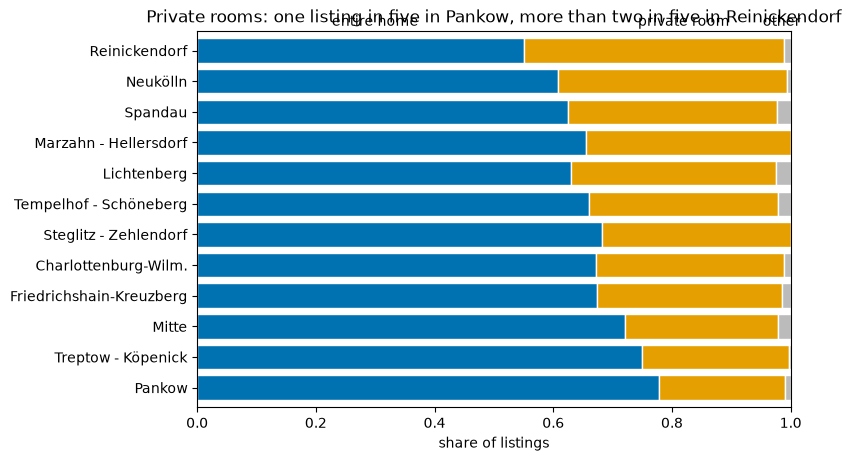

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print(sns.color_palette("colorblind").as_hex()[:3])   # ['#0173b2', '#de8f05', '#029e73']
OKABE_ITO = {"Entire home/apt": "#0072B2", "Private room": "#E69F00", "other": "#BBBBBB"}   # one fixed colour per group

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
group = listings["room_type"].where(listings["room_type"].isin(["Entire home/apt", "Private room"]), "other")
share = pd.crosstab(listings["district"], group, normalize="index")[list(OKABE_ITO)].sort_values("Private room")
print(share.loc[["Pankow", "Reinickendorf"]].round(3))
# room_type      Entire home/apt  Private room  other
# district
# Pankow                   0.779         0.211  0.010
# Reinickendorf            0.551         0.438  0.011

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
share.plot.barh(stacked=True, ax=ax, width=0.8, color=OKABE_ITO, edgecolor="white", legend=False)
for label, x in [("entire home", 0.3), ("private room", 0.82), ("other", 0.985)]:
    ax.text(x, len(share) - 0.3, label, ha="center", va="bottom")   # direct labels instead of a legend
ax.set(xlabel="share of listings", ylabel="",
       title="Private rooms: one listing in five in Pankow, more than two in five in Reinickendorf")

### In practice

- The Web Content Accessibility Guidelines (WCAG 2.1, success criterion 1.4.1) require that colour is not the only visual means of conveying information.
- matplotlib replaced the rainbow colour map "jet" by viridis as its default in version 2.0 (2017), because jet distorts perceived differences.
- Weather services use sequential palettes for precipitation and diverging palettes for temperature anomalies.

> **Caution.** **Rainbow colour maps** (jet, rainbow) create apparent boundaries where the data change smoothly and are unreadable in greyscale. Use viridis, cividis or a single-hue ramp for magnitudes. The extras notebooks [extras/05-seaborn-color-palettes.ipynb](extras/05-seaborn-color-palettes.ipynb) (seaborn documentation) and [extras/06-matplotlib-colormaps.ipynb](extras/06-matplotlib-colormaps.ipynb) (matplotlib documentation) explain why; the second one plots the lightness of every colour map and simulates greyscale printing and colour vision deficiencies.

## seaborn: statistical plots and small multiples

### Concept

**seaborn** draws statistical charts from a DataFrame in **long format** (one row per observation). You name the columns for x, y, colour (`hue`) and panels (`col`, `row`). Figure-level functions such as `displot`, `relplot` and `catplot` return a grid of Axes.

**Small multiples** are a series of small charts with the same axes, one per group. They avoid overlapping lines or histograms and let the eye compare shapes across panels. Shared axes make panels comparable; unshared axes (`sharey=False`) show the shape within each panel but must be pointed out to the reader.

### Why it matters

Comparing groups is the most frequent analytical task. Small multiples scale to many groups, where colour alone fails beyond four or five categories.

### How it works in Python

(1, 3)


{'Mitte': 3292, 'Neukölln': 907, 'Spandau': 111}


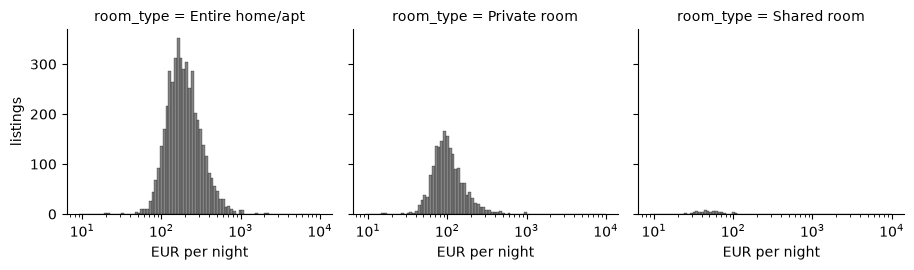

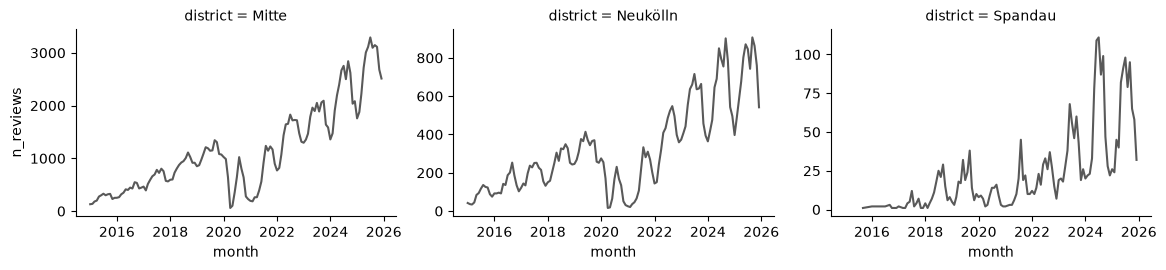

In [6]:
import pandas as pd
import seaborn as sns

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)]

g = sns.displot(short, x="price", col="room_type", col_order=["Entire home/apt", "Private room", "Shared room"],
                log_scale=True, height=2.8, aspect=1.1, color="0.35")   # one panel per room type
g.set_axis_labels("EUR per night", "listings")
print(g.axes.shape)                                                   # (1, 3)

monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
monthly = monthly.merge(listings[["id", "district"]], left_on="listing_id", right_on="id")
by_district = (monthly[monthly["district"].isin(["Mitte", "Neukölln", "Spandau"])
                       & monthly["month"].between("2015-01-01", "2025-12-01")]
               .groupby(["district", "month"])["n_reviews"].sum().reset_index())
sns.relplot(by_district, x="month", y="n_reviews", col="district", kind="line",
            height=2.8, aspect=1.4, color="0.35", facet_kws={"sharey": False})
print(by_district.groupby("district")["n_reviews"].max().to_dict())
# {'Mitte': 3292, 'Neukölln': 907, 'Spandau': 111}: the busiest month per district

With `sharey=False` each panel has its own scale, so the seasonal shape is visible in every district: Mitte has about 30 times as many reviews per month as Spandau, which the panels no longer show. Say so in the caption, or keep the shared axis.

### In practice

- Public health reports show infection curves per region as small multiples.
- Climate science uses panels of temperature anomalies by month or region.
- Product analytics compares conversion funnels per market in a grid of identical charts.

> **Note.** The seaborn tutorials [extras/03-seaborn-distributions.ipynb](extras/03-seaborn-distributions.ipynb) and [extras/04-seaborn-categorical.ipynb](extras/04-seaborn-categorical.ipynb) (seaborn documentation) cover histograms, kernel density estimates, box plots, violin plots and point plots with confidence intervals.

## Interactive charts with Plotly Express

### Concept

**Plotly** draws charts in the browser. **Plotly Express** (`plotly.express as px`) creates a complete figure in one call from a long-format DataFrame, with arguments similar to seaborn: `x`, `y`, `color`, `facet_col`. The reader can hover to read exact values, zoom and hide series by clicking the legend.

A figure consists of **traces** (one per series, in `fig.data`) and a **layout** (axes, title, legend). `fig.update_layout` changes the layout; `fig.write_html` saves a self-contained file that anyone can open in a browser without Python.

### Why it matters

Interactive charts let readers explore detail without the analyst producing dozens of static charts, for example the curve of their own district among twelve. They are the building blocks of dashboards, including the Streamlit app of block 2 ([06-lecture-testing-and-communicating.ipynb](06-lecture-testing-and-communicating.ipynb)).

### How it works in Python

In [7]:
import pandas as pd
import plotly.express as px

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
monthly = monthly.merge(listings[["id", "district"]], left_on="listing_id", right_on="id")
districts = ["Mitte", "Friedrichshain-Kreuzberg", "Pankow", "Neukölln"]
by_district = (monthly[monthly["district"].isin(districts) & monthly["month"].between("2015-01-01", "2026-05-01")]
               .groupby(["district", "month"])["n_reviews"].sum().reset_index())
fig = px.line(by_district, x="month", y="n_reviews", color="district",
              category_orders={"district": districts},
              color_discrete_sequence=["#0072B2", "#E69F00", "#009E73", "#D55E00"],
              labels={"month": "", "n_reviews": "reviews per month", "district": "district"},
              title="Reviews per month of today's Berlin listings, four districts")
fig.update_layout(hovermode="x unified")
print(len(fig.data), [trace.name for trace in fig.data])
# 4 ['Mitte', 'Friedrichshain-Kreuzberg', 'Pankow', 'Neukölln']
import tempfile                                          # save outside the repository
fig.write_html(Path(tempfile.gettempdir()) / "reviews_per_month.html", include_plotlyjs="cdn")   # open in a browser

4 ['Mitte', 'Friedrichshain-Kreuzberg', 'Pankow', 'Neukölln']


### In practice

- Statistical offices such as Eurostat publish interactive charts so that users can read the value for their own country.
- Our World in Data publishes every chart as an interactive graphic with a downloadable table.
- Research groups share interactive HTML figures as supplementary material.

> **Warning.** Interactivity is not a substitute for a clear static view. Hover text is invisible in a printed report or a screenshot, so the default view must already show the finding.

> 📖 **Read more:** [extras/07-plotly-express.ipynb](extras/07-plotly-express.ipynb) (Plotly documentation): a gallery of Plotly Express chart types, from scatter and line charts to facets, maps and animations.

> 📖 **Read more:** [extras/08-plotly-express-styling.ipynb](extras/08-plotly-express-styling.ipynb) (Plotly documentation): styles a Plotly Express figure through its own arguments (labels, colour sequences, category order, hover data), through `update_layout` afterwards and through templates, and sets defaults for all figures of a project.

## Critique and improve a chart

### Concept

A chart critique asks four questions:

1. **Question**: which comparison should the reader make?
2. **Encoding**: is that comparison shown by position or length on a common scale?
3. **Accuracy**: do the axes start where they should; are units and population stated?
4. **Clarity**: is there anything the reader must decode that could be labelled directly?

![A poorly designed bar chart of reviews per year with a truncated axis and rainbow colours next to a bar chart from zero that highlights the pandemic years, with a finding as its title](../figures/good-vs-poor-chart.png)

The left chart shows the number of reviews per year for today's Berlin listings (from `reviews_monthly`). It truncates the axis at 20,000, so the pandemic dip of 2020 looks like a fall to almost nothing and the bars for 2015 and 2016 vanish; the rainbow colours encode nothing; the title says nothing. The right chart starts at zero, uses colour for the one distinction the reader should see (the pandemic years 2020 and 2021), and states the finding in the title. The caption names a limitation: only listings that still exist in 2026 are counted, so earlier years are understated.

### Why it matters

Most analyses reach decision makers as one chart and a few sentences. Spotting and repairing misleading charts, including one's own, is a core professional skill.

### How it works in Python

{2019: 53965, 2020: 26499, 2021: 35447, 2022: 70471}


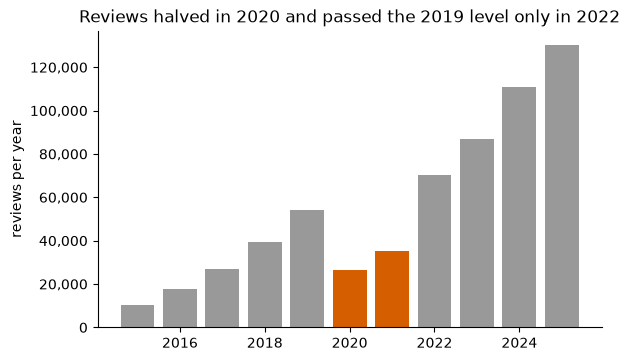

In [8]:
import matplotlib.pyplot as plt
import pandas as pd

monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")
yearly = monthly.groupby(monthly["month"].dt.year)["n_reviews"].sum().loc[2015:2025]
print(yearly.loc[[2019, 2020, 2021, 2022]].to_dict())
# {2019: 53965, 2020: 26499, 2021: 35447, 2022: 70471}

fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
colours = ["#D55E00" if year in (2020, 2021) else "0.6" for year in yearly.index]
ax.bar(yearly.index, yearly, color=colours)            # full axis from zero (bar default)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set(ylabel="reviews per year",
       title="Reviews halved in 2020 and passed the 2019 level only in 2022")
ax.spines[["top", "right"]].set_visible(False)

A line chart need not start at zero when the reader compares changes rather than magnitudes, but then the axis label must make the range obvious. Bars must always start at zero.

### In practice

- The UK Government Analysis Function advises against breaking the numerical axis of bar charts because it distorts the proportions between bars.
- The Financial Times' *Chart Doctor* column publishes before-and-after redesigns of published charts.
- The CONSORT guidelines for reporting clinical trials require absolute numbers alongside relative effects, for the same reason that bars start at zero.

> **Important.** **Worked example.** What does a night in Berlin cost, and where? Part A of the case-study notebook [04-case-study-airbnb-exploration.ipynb](04-case-study-airbnb-exploration.ipynb) plots the price distribution of short-stay listings by room type, the median price and the number of listings by district, and the reviews per month since 2015. The poor chart above (code in [`figures/make_figures.py`](../figures/make_figures.py)) can be improved with the four critique questions.

## Check your understanding

1. Which chart would you choose for "Are entire homes in Mitte more expensive than in Neukölln?" and why?
2. Rank position, angle, area and colour saturation by how accurately people decode them.
3. Name two ways to make a chart readable without relying on colour.
4. When is it acceptable for a y-axis not to start at zero?
5. What is lost when a dashboard chart is printed, and how do you design for it?

## Further reading

- Wilke, C. O. (2019). *Fundamentals of Data Visualization*. O'Reilly. Free online: <https://clauswilke.com/dataviz/>
- Healy, K. (2018). *Data Visualization: A Practical Introduction*, chapter 1 "Look at data". Princeton University Press. <https://socviz.co/lookatdata.html>
- Cleveland, W. S., & McGill, R. (1984). Graphical perception: Theory, experimentation, and application to the development of graphical methods. *Journal of the American Statistical Association*, 79(387), 531–554. <https://doi.org/10.1080/01621459.1984.10478080>
- Government Analysis Function (2023). *Data visualisation: charts*. UK Government. <https://analysisfunction.civilservice.gov.uk/policy-store/data-visualisation-charts/>